## Milestone 6: Predictive Model - Demand Forecast

Two forecasts were built and validated against simple baselines using time-based splits only (no random splitting):

**Monthly units per store and per product**

Thishich answers business question Q5.

**Daily total units, 7 days ahead**

As an operational extra.

Both use the same final test window (1 Sep to 31 Oct 2026).


### Part 1: Monthly forecast per store and product (Q5)

**Setup.** 

Monthly units per store (10) and per product (15) over 22 months. The last 2 months (Sep and Oct 2026) are the test set, forecast using only data up to Aug 2026.

**Baselines.**

- Naive: next month = last month.
- 3-month moving average.
- Same-month-last-year was not used because it needs 24 months and only 22 are available.

**Model.** 

Average units per day over all available months, multiplied by the number of days in the target month. The window length was chosen on a validation period (forecasting Jun and Jul 2026 from data through May), not on the test months.
Longer windows were better there, with all history best at both levels (store 5.7%, product 4.6% vs 6.5% and 6.0% for the plain 3-month average).

**Test results (Sep and Oct 2026, WAPE)**

| Level | Naive | 3-month average | Model |
|-------|------|------|------|
| Store | 7.0% | 5.4% | 5.5% |
| Product | 7.4% | 6.0% | 5.2% |

**Rolling back-test.**
The same 2-month forecast was repeated from 15 starting points.

| Mean WAPE | 3-month average | Model | Windows won by model |
|-----------|-----------------|-------|----------------------|
| Store | 6.3% | 5.7% | 13 of 15 |
| Product | 6.1% | 4.9% | 14 of 15 |

**Conclusion.**
Store-level WAPE is well below the 15% target (5.5% on the test months).
At product level the model beats the best baseline on the test months.
At store levelit is level with the best baseline on the test months (5.5% vs 5.4%) but better on average across the back-test windows.

### Part 2: Daily total forecast, 7 days ahead

**Target.** 

Total units sold per day, all stores combined (669 days, no gaps).

**Horizon.** 

7 days ahead: each day is predicted using sales up to 7 days earlier.

**Baseline.** 

Same weekday last week (also tested: training weekday average).

**Model.**
Random Forest Regressor (300 trees). Features: day of week, month, day of month, promotion flag, sales 7 days earlier, and the average of days 7 to 34 earlier.

**Validation.**

- Hold-out: trained before 1 Sep 2026, tested on 1 Sep to 31 Oct 2026 (61 days).
- Rolling-origin cross-validation: 5 folds of 61 days, each trained only on earlier dates.

**Metrics.** 

MAE (units/day) and WAPE (sum of absolute errors / sum of actual units).

| Fold | Test starts | Baseline WAPE | Random Forest WAPE |
|---|---|---|---|
| 1 | 2025-12-31 | 14.8% | 12.6% |
| 2 | 2026-03-02 | 15.2% | 11.3% |
| 3 | 2026-05-02 | 12.4% | 13.1% |
| 4 | 2026-07-02 | 11.5% | 9.0% |
| 5 | 2026-09-01 | 13.7% | 10.2% |
| Mean | | 13.5% | 11.2% |

Hold-out result: MAE 30.6 vs 40.9 for the baseline (WAPE 10.2% vs 13.7%).

**Findings.** 

The model beat the baseline in 4 of 5 folds (mean WAPE 11.2% vs 13.5%) but not in fold 3. 
Sales one week earlier is the strongest predictor; the promotion
Flag adds almost nothing, consistent with Milestone 5.

### conclusion

Both forecasts improve on their baselines on average, and the monthly store-level error (5.5%) is far inside the 15% target. Demand in this dataset is stable, so most of the predictable signal is the weekday pattern (daily) and the long-run average (monthly).

### Limitations

- The data is synthetic and covers under two years, so there is no full annual cycle to learn from.
- Demand is flat with no clear trend or seasonality, so simple averages are hard to beat by much.
- The monthly test covers only 2 months, and back-test windows overlap, so they are not independent trials.
- The Random Forest was not tuned.
- One day (28 Feb 2026, 568 units) is an unexplained spike.



days present: 669 | days expected: 669
missing days: 0
count    669.0
mean     298.3
std       58.9
min      179.0
25%      255.0
50%      283.0
75%      335.0
max      568.0
Name: units, dtype: float64


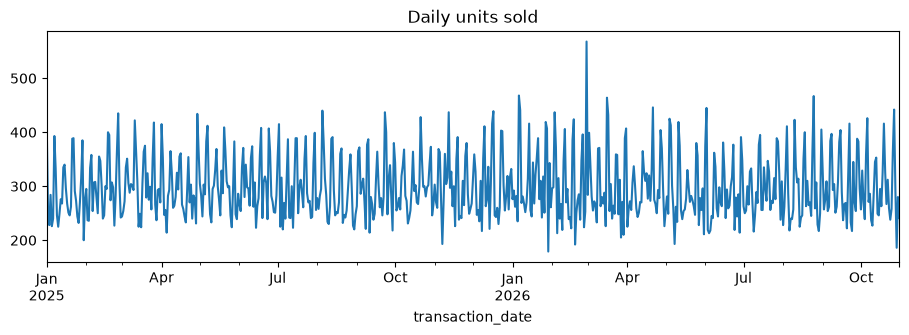

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sales = pd.read_csv("../data/processed/sales_clean.csv", parse_dates=["transaction_date"])

demand = (
    sales.groupby("transaction_date")["quantity"].sum()
    .rename("units")
    .to_frame()
)

# check for missing dates
full_range = pd.date_range(demand.index.min(), demand.index.max(), freq="D")
print("days present:", len(demand), "| days expected:", len(full_range))
print("missing days:", len(full_range.difference(demand.index)))

print(demand["units"].describe().round(1))

demand["units"].plot(figsize=(11, 3), title="Daily units sold")
plt.show()

In [2]:
# the biggest days
print(demand.nlargest(8, "units"))

# weekly pattern
demand["dow"] = demand.index.day_name()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
print(demand.groupby("dow")["units"].agg(["mean", "median", "max"]).round(0).reindex(order))

                  units
transaction_date       
2026-02-28          568
2026-01-06          468
2026-08-25          467
2026-03-16          464
2026-04-21          446
2026-06-02          445
2026-10-27          442
2026-01-07          441
            mean  median  max
dow                          
Monday     307.0   295.0  464
Tuesday    370.0   360.0  468
Wednesday  339.0   360.0  441
Thursday   266.0   268.0  324
Friday     269.0   266.0  345
Saturday   271.0   266.0  568
Sunday     267.0   266.0  360


In [3]:
demand = demand[["units"]]          # drop the helper column

cutoff = "2026-09-01"
train = demand[demand.index < cutoff]
test = demand[demand.index >= cutoff]
print(len(train), len(test), train.index.max().date(), test.index.min().date())

def mae(y, yhat):
    return np.abs(np.asarray(y) - np.asarray(yhat)).mean()

def wape(y, yhat):
    return np.abs(np.asarray(y) - np.asarray(yhat)).sum() / np.asarray(y).sum()

y_test = test["units"]

# Baseline 1: same weekday last week
naive = demand["units"].shift(7).loc[test.index]

# Baseline 2: average of that weekday in the training period
wd_mean = train.groupby(train.index.dayofweek)["units"].mean()
wd_avg = test.index.dayofweek.map(wd_mean)

results = pd.DataFrame({
    "MAE": [mae(y_test, naive), mae(y_test, wd_avg)],
    "WAPE": [wape(y_test, naive), wape(y_test, wd_avg)],
}, index=["Same weekday last week", "Weekday average (train)"]).round(3)
print(results)

608 61 2026-08-31 2026-09-01
                            MAE   WAPE
Same weekday last week   40.885  0.137
Weekday average (train)  41.252  0.138


In [4]:
from sklearn.ensemble import RandomForestRegressor

# promo flag per day
promo_day = sales.groupby("transaction_date")["promo_id"].apply(lambda s: (s != "PROMO_NONE").any())

feat = demand.copy()
feat["dow"] = feat.index.dayofweek
feat["month"] = feat.index.month
feat["day"] = feat.index.day
feat["is_promo"] = promo_day.reindex(feat.index).astype(int)
feat["lag_7"] = feat["units"].shift(7)
feat["roll_28"] = feat["units"].shift(7).rolling(28).mean()

feat = feat.dropna()   # first ~34 days have no history

X_cols = ["dow", "month", "day", "is_promo", "lag_7", "roll_28"]
X_train = feat.loc[feat.index < cutoff, X_cols]
y_train = feat.loc[feat.index < cutoff, "units"]
X_test = feat.loc[feat.index >= cutoff, X_cols]
y_test = feat.loc[feat.index >= cutoff, "units"]

rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print("Random Forest  MAE", round(mae(y_test, pred), 3), " WAPE", round(wape(y_test, pred), 3))
print(pd.Series(rf.feature_importances_, index=X_cols).sort_values(ascending=False).round(3))

Random Forest  MAE 30.567  WAPE 0.102
lag_7       0.625
dow         0.117
roll_28     0.107
day         0.085
month       0.056
is_promo    0.010
dtype: float64


In [5]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5, test_size=61)
rows = []
for i, (tr, te) in enumerate(tscv.split(feat), 1):
    m = RandomForestRegressor(n_estimators=300, random_state=42)
    m.fit(feat.iloc[tr][X_cols], feat.iloc[tr]["units"])
    yt = feat.iloc[te]["units"]
    rows.append({
        "fold": i,
        "test_start": feat.index[te[0]].date(),
        "baseline_WAPE": wape(yt, feat.iloc[te]["lag_7"]),
        "RF_WAPE": wape(yt, m.predict(feat.iloc[te][X_cols])),
    })

cv = pd.DataFrame(rows).round(3)
print(cv)
print(cv[["baseline_WAPE", "RF_WAPE"]].mean().round(3))

   fold  test_start  baseline_WAPE  RF_WAPE
0     1  2025-12-31          0.148    0.126
1     2  2026-03-02          0.152    0.113
2     3  2026-05-02          0.124    0.131
3     4  2026-07-02          0.115    0.090
4     5  2026-09-01          0.137    0.102
baseline_WAPE    0.135
RF_WAPE          0.112
dtype: float64


In [6]:
sales["month"] = sales["transaction_date"].dt.to_period("M").dt.to_timestamp()

store_m = sales.groupby(["store_id", "month"])["quantity"].sum().unstack("month")
prod_m = sales.groupby(["product_id", "month"])["quantity"].sum().unstack("month")

print("store table:", store_m.shape, "| product table:", prod_m.shape)   # expect (10, 22) and (15, 22)
print(store_m.isna().sum().sum(), "missing store-months,", prod_m.isna().sum().sum(), "missing product-months")

print(store_m.sum().astype(int).to_string())          # total units per month
print(store_m.mean(axis=1).round(0).to_string())      # average monthly units per store
print(prod_m.mean(axis=1).round(0).to_string())       # average monthly units per product

store table: (10, 22) | product table: (15, 22)
0 missing store-months, 0 missing product-months
month
2025-01-01    8899
2025-02-01    8472
2025-03-01    9351
2025-04-01    8939
2025-05-01    9335
2025-06-01    9051
2025-07-01    9300
2025-08-01    9028
2025-09-01    9071
2025-10-01    9280
2025-11-01    8971
2025-12-01    9388
2026-01-01    9508
2026-02-01    8517
2026-03-01    9360
2026-04-01    8878
2026-05-01    8918
2026-06-01    8728
2026-07-01    9176
2026-08-01    9169
2026-09-01    9079
2026-10-01    9148
store_id
STR_001    902.0
STR_002    923.0
STR_003    907.0
STR_004    920.0
STR_005    911.0
STR_006    914.0
STR_007    879.0
STR_008    935.0
STR_009    882.0
STR_010    899.0
product_id
PRD_001    598.0
PRD_002    598.0
PRD_003    610.0
PRD_004    599.0
PRD_005    609.0
PRD_006    604.0
PRD_007    608.0
PRD_008    615.0
PRD_009    600.0
PRD_010    594.0
PRD_011    611.0
PRD_012    605.0
PRD_013    608.0
PRD_014    608.0
PRD_015    605.0


In [7]:
test_months = pd.to_datetime(["2026-09-01", "2026-10-01"])
last3 = pd.to_datetime(["2026-06-01", "2026-07-01", "2026-08-01"])
aug = pd.Timestamp("2026-08-01")

def wape(y, yhat):
    y = np.asarray(y, dtype=float)
    yhat = np.asarray(yhat, dtype=float)
    return np.abs(y - yhat).sum() / y.sum()

rows = []
for level, tab in [("store", store_m), ("product", prod_m)]:
    actual = tab[test_months]
    naive = pd.concat([tab[aug]] * 2, axis=1)
    ma3 = pd.concat([tab[last3].mean(axis=1)] * 2, axis=1)
    rows.append({"level": level,
                 "naive_WAPE": wape(actual, naive),
                 "MA3_WAPE": wape(actual, ma3)})

print(pd.DataFrame(rows).round(3))

     level  naive_WAPE  MA3_WAPE
0    store       0.070     0.054
1  product       0.074     0.060


In [8]:
def days_in(m):
    return pd.Timestamp(m).days_in_month

def rate_forecast(tab, origin, targets, n):
    cols = [c for c in tab.columns if c <= origin][-n:]
    days = pd.Series([days_in(c) for c in cols], index=cols)
    rate = (tab[cols] / days).mean(axis=1)                  # units per day
    return pd.concat([rate * days_in(t) for t in targets], axis=1)

val_origin = pd.Timestamp("2026-05-01")
val_targets = pd.to_datetime(["2026-06-01", "2026-07-01"])

rows = []
for n in [3, 6, 12, 17]:                                    # 17 = all months up to May 2026
    r = {"window_months": n}
    for level, tab in [("store", store_m), ("product", prod_m)]:
        f = rate_forecast(tab, val_origin, val_targets, n)
        r[f"{level}_WAPE"] = wape(tab[val_targets], f)
    rows.append(r)

# reference: plain 3-month average (no day adjustment) on the same validation window
last3 = [c for c in store_m.columns if c <= val_origin][-3:]
ref = {"window_months": "plain MA3"}
for level, tab in [("store", store_m), ("product", prod_m)]:
    f = pd.concat([tab[last3].mean(axis=1)] * 2, axis=1)
    ref[f"{level}_WAPE"] = wape(tab[val_targets], f)
rows.append(ref)

print(pd.DataFrame(rows).round(3))

  window_months  store_WAPE  product_WAPE
0             3       0.063         0.057
1             6       0.067         0.052
2            12       0.060         0.049
3            17       0.057         0.046
4     plain MA3       0.065         0.060


In [9]:
test_origin = pd.Timestamp("2026-08-01")
test_months = pd.to_datetime(["2026-09-01", "2026-10-01"])
n_all = len([c for c in store_m.columns if c <= test_origin])       # 20 months

res = []
for level, tab in [("store", store_m), ("product", prod_m)]:
    actual = tab[test_months]
    naive = pd.concat([tab[test_origin]] * 2, axis=1)
    last3 = [c for c in tab.columns if c <= test_origin][-3:]
    ma3 = pd.concat([tab[last3].mean(axis=1)] * 2, axis=1)
    model = rate_forecast(tab, test_origin, test_months, n_all)
    res.append({"level": level,
                "naive": wape(actual, naive),
                "MA3": wape(actual, ma3),
                "model (all-history daily rate)": wape(actual, model)})

print(pd.DataFrame(res).round(3))

     level  naive    MA3  model (all-history daily rate)
0    store  0.070  0.054                           0.055
1  product  0.074  0.060                           0.052


In [10]:
months = list(store_m.columns)
rows = []
for i, origin in enumerate(months):
    if i < 5 or i + 2 >= len(months):      # need 6+ months of history and 2 target months
        continue
    targets = months[i + 1:i + 3]
    r = {"origin": origin.date()}
    for level, tab in [("store", store_m), ("product", prod_m)]:
        actual = tab[targets]
        ma3 = pd.concat([tab[months[i - 2:i + 1]].mean(axis=1)] * 2, axis=1)
        model = rate_forecast(tab, origin, targets, i + 1)
        r[f"{level}_MA3"] = wape(actual, ma3)
        r[f"{level}_model"] = wape(actual, model)
    rows.append(r)

bt = pd.DataFrame(rows)
print(bt.round(3).to_string(index=False))
print(bt.drop(columns="origin").mean().round(3))
print("model beats MA3 at store level in", (bt.store_model < bt.store_MA3).sum(), "of", len(bt),
      "windows; at product level in", (bt.product_model < bt.product_MA3).sum(), "of", len(bt))

    origin  store_MA3  store_model  product_MA3  product_model
2025-06-01      0.070        0.061        0.056          0.048
2025-07-01      0.073        0.058        0.060          0.054
2025-08-01      0.057        0.056        0.050          0.051
2025-09-01      0.067        0.065        0.054          0.052
2025-10-01      0.049        0.050        0.058          0.048
2025-11-01      0.047        0.040        0.057          0.043
2025-12-01      0.073        0.055        0.081          0.051
2026-01-01      0.089        0.073        0.068          0.045
2026-02-01      0.064        0.064        0.058          0.047
2026-03-01      0.055        0.054        0.070          0.057
2026-04-01      0.068        0.061        0.060          0.055
2026-05-01      0.065        0.057        0.060          0.046
2026-06-01      0.054        0.049        0.063          0.042
2026-07-01      0.057        0.052        0.055          0.043
2026-08-01      0.054        0.055        0.060        